# Project 1: Wholesale Customer Segmentation

**Course:** DSC8307 Data Mining, Modeling and Analytics  
**Programme:** MSc Data Science and Analytics  


## Task

Segment wholesale customers by spending behaviour and recommend how the distributor could serve each segment differently.

1. Explore and write a short report on the data and carryout necessary data preparation, with justification. Determine the cluster tendency of the data.

2. Compare the quality and interpretability of partitioning, hierarchical and density-based clustering on the data.

3. Assign descriptive names to the resulting clusters and comment on the customers’ spending habits.

### Setup & Imports

In [1]:
# --- Standard library ---
import os
import warnings
from pathlib import Path

# --- Core data handling ---
import numpy as np
import pandas as pd

# --- Visualisation ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- Preprocessing & decomposition ---
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# --- Clustering ---
import sklearn, scipy
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from scipy.cluster.hierarchy import dendrogram, linkage, cophenet
from scipy.spatial.distance import pdist

# --- Cluster evaluation ---
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
)
from sklearn.neighbors import NearestNeighbors       # for DBSCAN k-distance plot

# --- Reproducibility & display ---
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# --- Plotting defaults ---
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"

# --- Paths ---
DATA_PATH = Path("wholesale-customers.csv")
assert DATA_PATH.exists(), (
    f"Dataset not found at '{DATA_PATH.resolve()}'. "
    "Place 'wholesale-customers.csv' in the same folder as this notebook."
)

print("Environment ready.")
print(f"  numpy       : {np.__version__}")
print(f"  pandas      : {pd.__version__}")
print(f"  seaborn     : {sns.__version__}")
print(f"  RANDOM_STATE: {RANDOM_STATE}")
print(sklearn.__version__, scipy.__version__)

Environment ready.
  numpy       : 2.3.5
  pandas      : 2.3.3
  seaborn     : 0.13.2
  RANDOM_STATE: 42
1.7.2 1.16.3


### Loading Data & Initial Inspection

In [2]:
df = pd.read_csv(DATA_PATH)

print(f"Shape: {df.shape}")

df.head()

Shape: (440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


### Data Quality Checks

In [3]:
print(f"Dtypes:\n{df.dtypes}")
print(f"\nMissing values:\n{df.isna().sum()}")
print(f"\nDuplicate rows: {df.duplicated().sum()}")

quality = pd.DataFrame({
    "n_negative": (df < 0).sum(),
    "n_zero":     (df == 0).sum(),
})
quality

Dtypes:
Channel             int64
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicatessen        int64
dtype: object

Missing values:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicatessen        0
dtype: int64

Duplicate rows: 0


,n_negative,n_zero
Channel,0,0
Region,0,0
Fresh,0,0
Milk,0,0
Grocery,0,0
Frozen,0,0
Detergents_Paper,0,0
Delicatessen,0,0


In [4]:
# Checking the validity of the nominal variables
expected_domains = {"Channel": {1, 2}, "Region": {1, 2, 3}}
for c, domain in expected_domains.items():
    observed = set(df[c].unique())
    print(f"{c}: observed={sorted(observed)}, unexpected={sorted(observed - domain) or 'none'}")

Channel: observed=[np.int64(1), np.int64(2)], unexpected=none
Region: observed=[np.int64(1), np.int64(2), np.int64(3)], unexpected=none


### Dataset Overview and Initial Data Quality Assessment

The dataset contains 440 customer records and 8 variables, comprising six numerical spending variables (Fresh, Milk, Grocery, Frozen, Detergents_Paper and Delicatessen) and two categorical variables (Channel and Region).

An initial data quality assessment showed that all eight variables have integer data types. There were no missing values or duplicate records, indicating that the dataset is complete in these two respects.

The data were also checked for negative and zero values across all eight variables. No negative values were found, and no zero values were observed in any variable. For the six spending variables this indicates that every customer recorded positive annual expenditure in every product category. For Channel and Region, the absence of zeros or negatives is consistent with the documented category codes.

A further check compared the observed codes in the two categorical variables against their documented domains. Channel contained only the codes 1 and 2, and Region contained only the codes 1, 2 and 3. No undocumented codes were present in either variable, confirming that the categorical encodings are valid.

The first five records were inspected to understand the dataset structure and confirm that the spending variables contain numerical values, while Channel and Region contain encoded categorical values.

Overall, the dataset is structurally complete.

### Distribution & Summary Statistics

In [5]:
spend_cols = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicatessen"]

# Summary statistics for the six spend variables
summary = df[spend_cols].describe().T          # count, mean, std, min, quartiles, max
summary["skew"]     = df[spend_cols].skew()     # asymmetry of each distribution
summary["kurtosis"] = df[spend_cols].kurtosis() # tail weight relative to a normal distribution
summary

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
Fresh,440.00,"12,000.30","12,647.33",3.00,"3,127.75","8,504.00","16,933.75","112,151.00",2.56,11.54
Milk,440.00,"5,796.27","7,380.38",55.00,"1,533.00","3,627.00","7,190.25","73,498.00",4.05,24.67
Grocery,440.00,"7,951.28","9,503.16",3.00,"2,153.00","4,755.50","10,655.75","92,780.00",3.59,20.91
Frozen,440.00,"3,071.93","4,854.67",25.00,742.25,"1,526.00","3,554.25","60,869.00",5.91,54.69
Detergents_Paper,440.00,"2,881.49","4,767.85",3.00,256.75,816.50,"3,922.00","40,827.00",3.63,19.01
Delicatessen,440.00,"1,524.87","2,820.11",3.00,408.25,965.50,"1,820.25","47,943.00",11.15,170.69


In [6]:
# Frequency-based summary for the two categorical variables
for c in ["Channel", "Region"]:
    counts = df[c].value_counts().sort_index()                             # number of customers per code
    props  = df[c].value_counts(normalize=True).sort_index().mul(100).round(1)  # percentage share per code
    print(f"\n{c}:")
    print(pd.DataFrame({"count": counts, "percent": props}).rename_axis("code"))


Channel:
      count  percent
code                
1       298    67.70
2       142    32.30

Region:
      count  percent
code                
1        77    17.50
2        47    10.70
3       316    71.80


### Descriptive Statistical Analysis

Descriptive statistics were calculated for the six annual spending variables to examine their central tendency, variability and distribution.

The results show considerable variation in customer spending across product categories. Fresh products recorded the highest mean annual expenditure (12,000.30 m.u.), followed by Grocery (7,951.28 m.u.) and Milk (5,796.27 m.u.). Delicatessen recorded the lowest mean expenditure at 1,524.87 m.u. Across all six categories, the mean spending values were considerably higher than the medians, suggesting that a relatively small number of customers account for substantially higher expenditure.

All six spending variables exhibit positive skewness, ranging from 2.56 for Fresh to 11.15 for Delicatessen. This indicates strongly right-skewed distributions, where most customers record relatively lower expenditure while a smaller proportion spend considerably more. The high kurtosis values, particularly for Delicatessen (170.69) and Frozen (54.69), further indicate heavy-tailed distributions and the presence of extreme observations.

The categorical variables were examined using frequency distributions. For Channel, Horeca customers accounted for 67.70% (298) of the observations, while Retail customers represented 32.30% (142). Regarding Region, customers classified under Other accounted for the largest proportion at 71.80% (316), followed by Lisbon at 17.50% (77) and Oporto at 10.70% (47). These results indicate that the dataset is dominated by Horeca customers and customers from regions outside Lisbon and Oporto.

Overall, the descriptive analysis reveals substantial variation in customer spending, positively skewed distributions and unequal representation across customer channels and regions.

### Visual Distributions

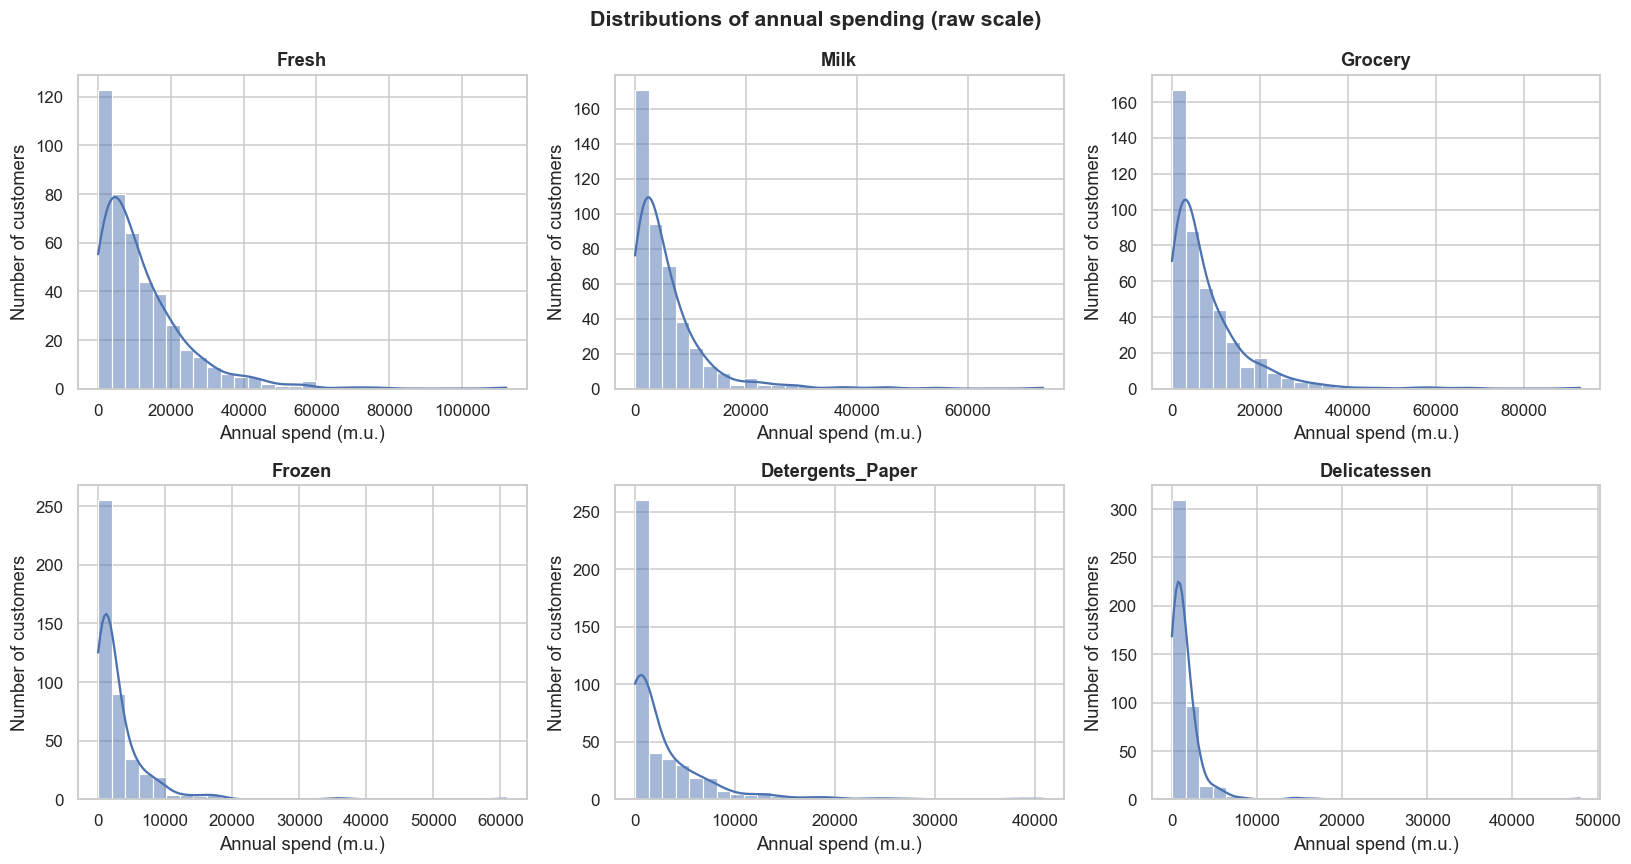

In [7]:
# Histograms of the six spend variables (raw scale) to inspect shape and skew
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, spend_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Annual spend (m.u.)")
    ax.set_ylabel("Number of customers")
fig.suptitle("Distributions of annual spending (raw scale)", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

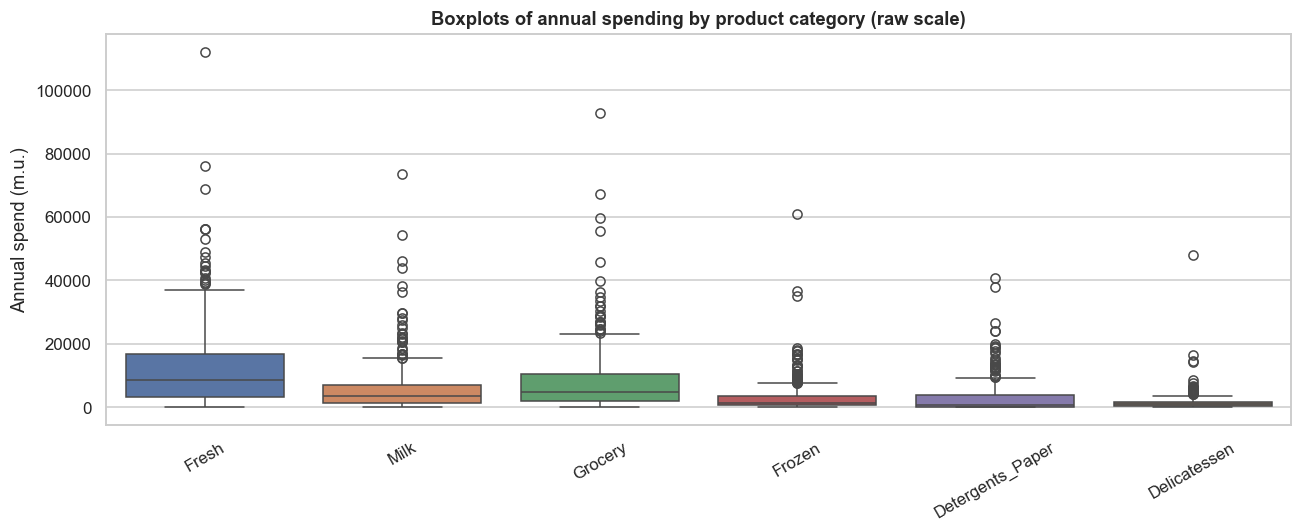

In [8]:
# Boxplots on the raw scale to expose outliers and compare ranges across categories
fig, ax = plt.subplots(figsize=(12, 5))
sns.boxplot(data=df[spend_cols], ax=ax)
ax.set_ylabel("Annual spend (m.u.)")
ax.set_title("Boxplots of annual spending by product category (raw scale)")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

### Distribution Analysis Using Histograms and Boxplots

The histograms confirm the patterns observed in the descriptive statistics. All six spending variables exhibit strongly right-skewed distributions, with most customers concentrated at the lower end of the spending range and a long right tail extending towards higher expenditure values. Delicatessen and Frozen display particularly pronounced skewness, with a small proportion of customers recording substantially higher spending than the majority.

The boxplots further illustrate these distributions, showing compressed interquartile ranges and numerous observations beyond the upper whiskers across all six variables. These observations are flagged as potential statistical outliers under the IQR rule. However, their presence does not necessarily indicate data errors, as they may represent genuine differences in customer purchasing behaviour. Removing these observations indiscriminately could eliminate high-spending customers and important purchasing patterns that the clustering analysis aims to identify.

The boxplots also reveal substantial differences in the scale and spread of the spending variables. For instance, Fresh has a median annual expenditure of approximately 8,504 m.u., compared with 966 m.u. for Delicatessen. Such differences mean that variables with larger numerical ranges could exert greater influence on distance calculations if the original features were used without scaling.

These observations inform two preparation steps before clustering: applying a logarithmic transformation to reduce the influence of extreme values and right-skewness, followed by standardisation to place all six spending variables on a comparable scale. These preprocessing steps are implemented in the subsequent analysis.

### Categorical Profiles

In [9]:
# ============================================================
# Categorical Profiles
# ============================================================
# Mapping the numeric codes to their documented names for clearer interpretation, then calculating the mean 
# spending per category for each Channel and Region.

# Defining the mappings based on the CRAN randomMachines documentation
channel_map = {1: "Horeca", 2: "Retail"}
region_map  = {1: "Lisbon", 2: "Oporto", 3: "Other"}

# Mapping the codes to names in a temporary copy of the dataframe
df_named = df.copy()
df_named["Channel"] = df_named["Channel"].map(channel_map)
df_named["Region"]  = df_named["Region"].map(region_map)

# Calculating mean spend by Channel and transpose so categories are rows
channel_profile = df_named.groupby("Channel")[spend_cols].mean().T

# Adding a ratio column to easily compare Retail against Horeca
channel_profile["Retail_to_Horeca_ratio"] = channel_profile["Retail"] / channel_profile["Horeca"]

print("Channel Spending Profiles:")
display(channel_profile)


# Calculating mean spend by Region and transpose 
region_profile = df_named.groupby("Region")[spend_cols].mean().T

print("\nRegion Spending Profiles:")
display(region_profile)

Channel Spending Profiles:


Channel,Horeca,Retail,Retail_to_Horeca_ratio
Fresh,"13,475.56","8,904.32",0.66
Milk,"3,451.72","10,716.50",3.10
Grocery,"3,962.14","16,322.85",4.12
Frozen,"3,748.25","1,652.61",0.44
Detergents_Paper,790.56,"7,269.51",9.20
Delicatessen,"1,415.96","1,753.44",1.24



Region Spending Profiles:


Region,Lisbon,Oporto,Other
Fresh,"11,101.73","9,887.68","12,533.47"
Milk,"5,486.42","5,088.17","5,977.09"
Grocery,"7,403.08","9,218.60","7,896.36"
Frozen,"3,000.34","4,045.36","2,944.59"
Detergents_Paper,"2,651.12","3,687.47","2,817.75"
Delicatessen,"1,354.90","1,159.70","1,620.60"


### Categorical Spending Profiles

The dataset description identifies `Channel` as either Horeca (Hotel/Restaurant/Cafe) or Retail, and `Region` as Lisbon, Oporto or Other. According to the [CRAN `randomMachines` package documentation](https://search.r-project.org/CRAN/refmans/randomMachines/html/whosale.html), which sources the dataset from the UCI Machine Learning Repository, the numeric codes map as follows:

- **Channel:** 1 = Horeca, 2 = Retail.
- **Region:** 1 = Lisbon, 2 = Oporto, 3 = Other.

The tables present the mean annual spending across the six product categories for each channel and region. The channel profiles reveal distinct differences in purchasing patterns between Horeca and Retail customers.

Retail customers spend considerably more on Grocery and Detergents_Paper, with mean expenditure approximately 4.1 and 9.2 times higher than that of Horeca customers, respectively. They also spend more on Milk and Delicatessen, although the differences are less pronounced. In contrast, Horeca customers spend more on Fresh and Frozen products, with mean expenditure approximately 1.5 and 2.3 times higher than Retail customers, respectively. These differences suggest that the two channels have distinct purchasing patterns, with Retail customers spending more on grocery and household-related products, while Horeca customers allocate more expenditure to Fresh and Frozen products.

The regional spending profiles are comparatively similar, although some differences are evident across product categories. Oporto records the highest mean expenditure on Grocery, Frozen and Detergents_Paper, while the Other region records the highest expenditure on Fresh, Milk and Delicatessen. Lisbon generally records lower mean expenditure across these categories. Although these differences indicate some regional variation in purchasing behaviour, the profiles do not reveal a clear separation between the three regions comparable to the differences observed between the two channels.

### Data Preparation (Log Transformation & Standardization (Scaling))

In [10]:
from sklearn.preprocessing import StandardScaler

# 1. Log-transforming to compress the right-skewed tails
df_log = df[spend_cols].apply(np.log1p)

# 2. Standardising to give all six variables equal weight in distance calculations
scaler = StandardScaler()
df_scaled = pd.DataFrame(
    scaler.fit_transform(df_log),
    columns=spend_cols,
    index=df.index
)

print("Skewness before vs after log1p transformation:")
skew_compare = pd.DataFrame({
    "raw_skew": df[spend_cols].skew(),
    "log_skew": df_log.skew()
})
skew_compare

Skewness before vs after log1p transformation:


,raw_skew,log_skew
Fresh,2.56,-1.58
Milk,4.05,-0.22
Grocery,3.59,-0.67
Frozen,5.91,-0.35
Detergents_Paper,3.63,-0.24
Delicatessen,11.15,-1.09


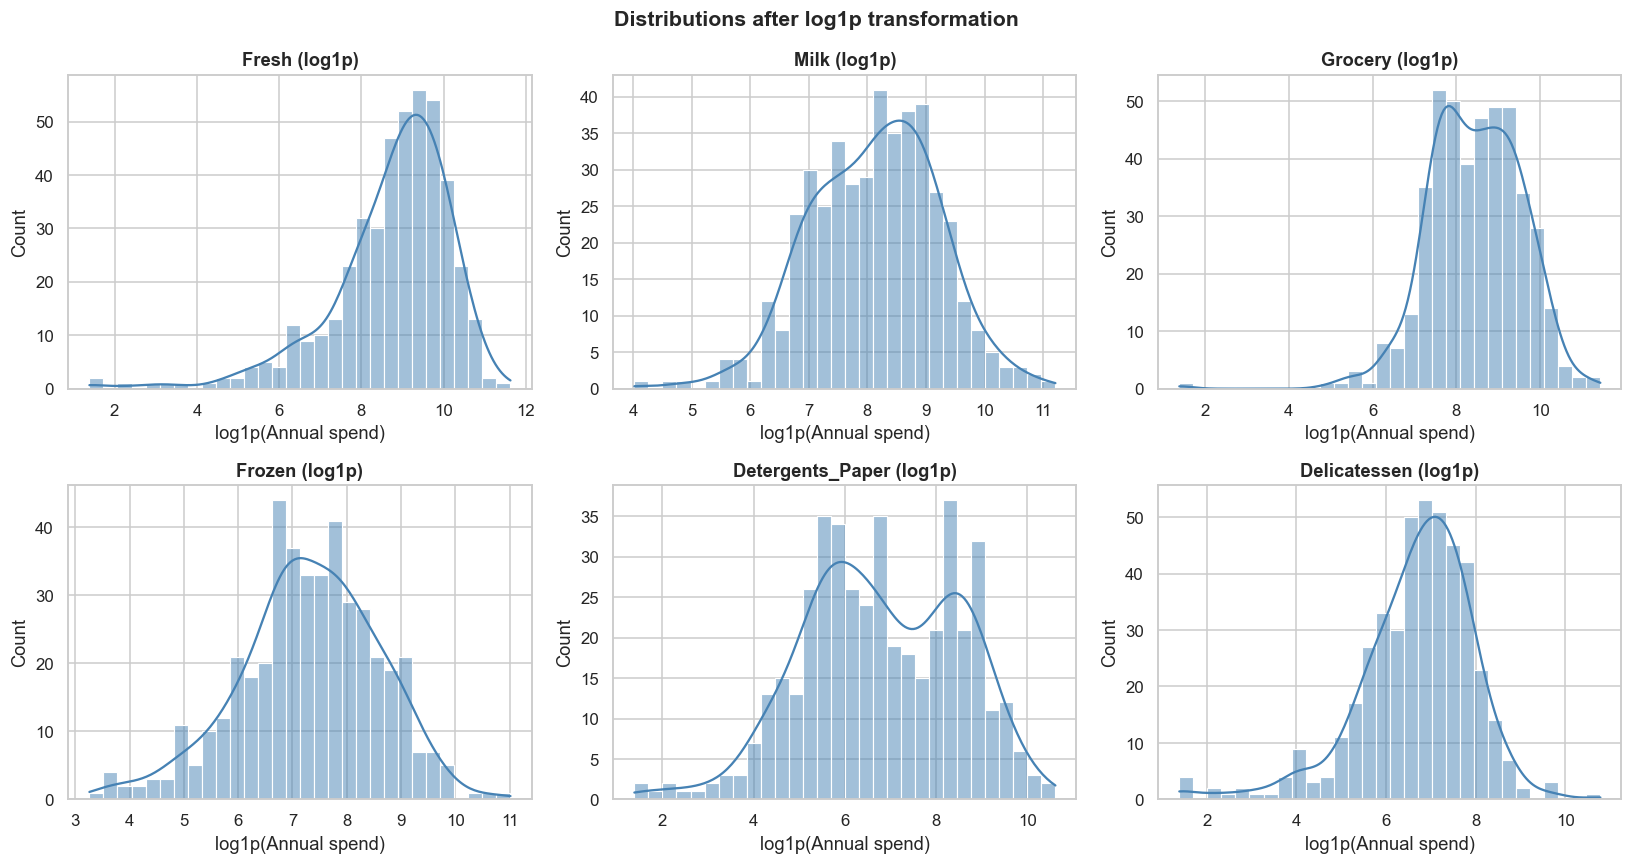

In [11]:
# Visual check: distributions after log1p
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, spend_cols):
    sns.histplot(df_log[col], bins=30, kde=True, ax=ax, color="steelblue")
    ax.set_title(f"{col} (log1p)")
    ax.set_xlabel("log1p(Annual spend)")
fig.suptitle("Distributions after log1p transformation", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

The preparation step applied two transformations to the six spending variables.

First, a `log1p` transformation was applied to compress the extreme right tails identified in the previous section. The comparison of skewness before and after the transformation shows a substantial change in the distributions:

- All six variables were strongly right-skewed on the raw scale, with skewness ranging from 2.56 to 11.15.
- After `log1p`, all six variables exhibited negative skewness, ranging from -1.58 to -0.22. This indicates that the transformation substantially reduced the original right-skewness, although the resulting distributions varied in their degree of negative skewness.

The histograms confirm this visually: the distributions are less compressed at the lower end and have shorter right tails compared with the original distributions. However, Fresh and Delicatessen retain more pronounced negative skewness than the other variables.

Second, a `StandardScaler` was applied to the log-transformed values. This centres each variable at zero and scales it to unit variance, making the six spending variables comparable for distance-based clustering. Without this step, categories with larger numerical ranges and variability, such as Fresh and Grocery, could exert greater influence on the distance calculations simply because of their larger numerical spread.

Removing these outliers could discard important high-spending customer patterns that the segmentation aims to identify. That's why log transformation was used instead to reduce the influence of large values by compressing their numerical differences rather than deleting the observations.

The transformed and scaled values are stored in `df_scaled`, which is the feature space used for all cluster tendency checks and clustering algorithms in the rest of the analysis. The raw `df` is retained unchanged for profiling and for the final, interpretable cluster summaries.


### Cluster Tendency

In [12]:
# Cluster Tendency (Hopkins Statistic)

def hopkins_statistic(X, m=None, random_state=42):
    """
    Computes the Hopkins statistic for cluster tendency.
    X: array-like of shape (n_samples, n_features)
    m: number of sample points (default is 10% of n_samples)
    """
    np.random.seed(random_state)
    n, d = X.shape
    if m is None:
        m = int(0.1 * n)
    
    # Uniformly sample m points from the feature space (within min/max bounds)
    X_min = X.min(axis=0)
    X_max = X.max(axis=0)
    U = np.random.uniform(X_min, X_max, size=(m, d))
    
    # Randomly select m actual data points
    idx = np.random.choice(n, m, replace=False)
    W = X[idx]
    
    # Nearest neighbor distance for uniform points (U to W)
    nbrs = NearestNeighbors(n_neighbors=1).fit(W)
    u_dist, _ = nbrs.kneighbors(U)
    
    # Nearest neighbor distance for actual points (W to W, excluding self)
    nbrs_w = NearestNeighbors(n_neighbors=2).fit(W)
    w_dist, _ = nbrs_w.kneighbors(W)
    w_dist = w_dist[:, 1] # exclude self
    
    H = u_dist.sum() / (u_dist.sum() + w_dist.sum())
    return H

# Calculating Hopkins on the scaled data
X_scaled = df_scaled.values
hopkins_val = hopkins_statistic(X_scaled, random_state=RANDOM_STATE)

print(f"Hopkins Statistic: {hopkins_val:.4f}")
if hopkins_val > 0.75:
    print("Result: Strong evidence of clustering tendency (H > 0.75).")
elif hopkins_val > 0.5:
    print("Result: Some clustering tendency, but not strong.")
else:
    print("Result: Data is likely uniformly distributed (no clustering tendency).")

Hopkins Statistic: 0.7516
Result: Strong evidence of clustering tendency (H > 0.75).


### Cluster Tendency (Hopkins Statistic)

Before applying clustering algorithms, it is important to assess whether the dataset exhibits an inherent tendency to form clusters rather than being randomly distributed.

The Hopkins statistic was calculated using the scaled feature space (`df_scaled`). It compares the nearest-neighbour distances of actual data points with those of randomly generated points.

- **Hopkins Statistic (H): 0.7516**

A value around 0.5 suggests a random spatial distribution, while values approaching 1 indicate a stronger clustering tendency. The obtained value of 0.7516 suggests that the wholesale customer data has a meaningful tendency to form clusters, supporting further analysis using partitioning, hierarchical and density-based clustering algorithms.

### K-Means Clustering (Finding the Best *k*)

,k,Inertia,Silhouette,Davies_Bouldin
0,2,"1,844.06",0.29,1.35
1,3,"1,553.42",0.26,1.34
2,4,"1,386.86",0.19,1.54
3,5,"1,266.15",0.19,1.48
4,6,"1,174.76",0.20,1.43
5,7,"1,086.36",0.20,1.39
6,8,"1,028.49",0.19,1.44
7,9,973.14,0.20,1.38
8,10,932.00,0.19,1.34


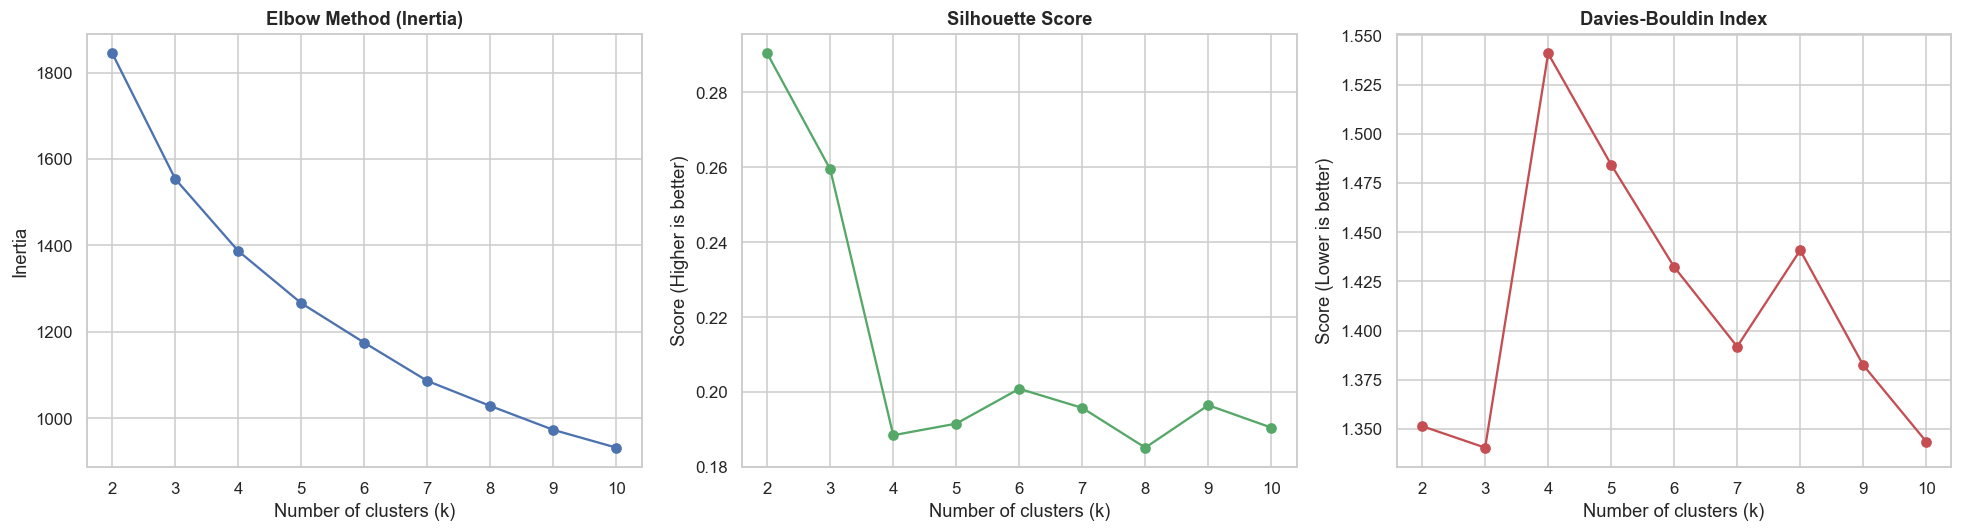

In [13]:
# ============================================================
# K-Means — Finding the optimal number of clusters (k)
# ============================================================
# Testing k from 2 to 10 and evaluating using three metrics:
# - Inertia (Elbow method)
# - Silhouette Score (higher is better)
# - Davies-Bouldin Index (lower is better)

k_range = range(2, 11)
inertias = []
silhouettes = []
db_scores = []

for k in k_range:
    # Fitting K-Means (using n_init=10 to avoid local optima)
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = kmeans.fit_predict(df_scaled)
    
    # Store metrics
    inertias.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(df_scaled, labels))
    db_scores.append(davies_bouldin_score(df_scaled, labels))

# Creating a summary DataFrame
k_eval = pd.DataFrame({
    "k": list(k_range),
    "Inertia": inertias,
    "Silhouette": silhouettes,
    "Davies_Bouldin": db_scores
})

display(k_eval)

# Plotting the metrics
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Elbow method
axes[0].plot(k_range, inertias, marker='o', color='b')
axes[0].set_title("Elbow Method (Inertia)")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

# 2. Silhouette Score
axes[1].plot(k_range, silhouettes, marker='o', color='g')
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Score (Higher is better)")

# 3. Davies-Bouldin Index
axes[2].plot(k_range, db_scores, marker='o', color='r')
axes[2].set_title("Davies-Bouldin Index")
axes[2].set_xlabel("Number of clusters (k)")
axes[2].set_ylabel("Score (Lower is better)")

plt.tight_layout()
plt.show()

### K-Means: Choosing the Number of Clusters (k)

To determine the optimal number of clusters, K-Means was run for \(k\) ranging from 2 to 10. Three internal validation metrics were used to evaluate the quality of the cluster structures:

- **Inertia (Elbow Method):** Measures within-cluster variance. We look for the point where the decrease in inertia slows down (the "elbow").
- **Silhouette Score:** Measures how well-separated the clusters are. Ranges from -1 to 1; *higher is better*.
- **Davies-Bouldin Index:** Measures the average similarity between clusters. *Lower is better*.

The validation metrics point to k = 2 or k = 3 as the strongest candidates. The Elbow Method shows inertia declining steadily with no sharp bend, though the largest drop after the first step occurs between k = 2 and k = 3 (1,844 to 1,553 to 1,387 at k = 4), with diminishing returns beyond that. The Silhouette Score is highest at k = 2 (0.29) but remains competitive at k = 3 (0.26), while the Davies-Bouldin Index is lowest at k = 3 (1.34). For k ≥ 4, the Silhouette Score falls to about 0.19 and the Davies-Bouldin Index peaks at 1.54, indicating overlapping clusters. Therefore k = 3 was selected, as it is the largest number of clusters that preserves acceptable separation while offering more granular, actionable customer segments than a binary split. Silhouette values below 0.3 indicate that the overall cluster structure is weak to moderate.

### Final K-Means Model & Cluster Profiling

In [14]:
# ============================================================
# Fitting final K-Means model (k=3) and profile clusters
# ============================================================

# 1. Fitting K-Means with k=3
kmeans_final = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE)
df["Cluster_KMeans"] = kmeans_final.fit_predict(df_scaled)

# 2. How many customers in each cluster?
cluster_counts = df["Cluster_KMeans"].value_counts().sort_index()
print("Cluster sizes:")
display(cluster_counts)

# 3. Profiling the clusters on the ORIGINAL (unscaled) spending data
# Using the original data so the numbers are in actual monetary units (m.u.)
cluster_profile = df.groupby("Cluster_KMeans")[spend_cols].mean().round(0)
display(cluster_profile)

# 4. Cross-tabulating clusters with Channel to see the Retail vs Horeca split
channel_crosstab = pd.crosstab(df["Cluster_KMeans"], df["Channel"])
channel_crosstab.columns = ["Horeca (1)", "Retail (2)"]
print("\nCluster vs. Channel:")
display(channel_crosstab)

# 5. Cluster vs. Region Cross-tabulation

# Mapping codes to names using the region_map defined earlier
df_named["Cluster_KMeans"] = df["Cluster_KMeans"]

region_crosstab = pd.crosstab(
    df_named["Cluster_KMeans"], 
    df_named["Region"]
)

print("Cluster vs. Region:")
display(region_crosstab)

Cluster sizes:


Cluster_KMeans
0     61
1    129
2    132
3    118
Name: count, dtype: int64

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
Cluster_KMeans,,,,,,
0,"2,809.00","7,062.00","12,349.00",566.00,"5,343.00",636.00
1,"19,374.00","4,068.00","4,445.00","6,184.00",723.00,"2,323.00"
2,"9,633.00","1,570.00","2,072.00","2,175.00",345.00,585.00
3,"11,339.00","11,759.00","16,088.00","1,968.00","6,806.00","2,164.00"



Cluster vs. Channel:


,Horeca (1),Retail (2)
Cluster_KMeans,,
0,21,40
1,122,7
2,131,1
3,24,94


Cluster vs. Region:


Region,Lisbon,Oporto,Other
Cluster_KMeans,,,
0,8,6,47
1,21,17,91
2,27,11,94
3,21,13,84


### K-Means Clustering Results (k = 3)

The K-Means algorithm segmented the 440 customers into three groups of 80, 147, and 213 customers. By profiling the clusters on the original (unscaled) spending data and cross-tabulating them with the `Channel` variable, three distinct behavioural segments emerge:

**Cluster 0: Grocery & Household-Focused Buyers (80 customers)**
- **Profile:** Skewed towards Retail (60%, but with 40% Horeca). This group has the lowest `Fresh` spending (2,899 m.u.) and lowest `Frozen` spending (607 m.u.). However, they have the highest `Detergents_Paper` spending (5,554 m.u.), alongside high `Grocery` (12,570 m.u.) and `Milk` (7,136 m.u.) spending.
- **Interpretation:** These are grocery-oriented buyers. They stock up on packaged goods, dairy, and cleaning supplies, with very little need for fresh produce.

**Cluster 1: High-Volume, Diversified Buyers (147 customers)**
- **Profile:** This is the highest-spending group across almost every category, led by `Fresh` (17,043 m.u.), `Grocery` (13,334 m.u.), and `Milk` (10,560 m.u.). It is mixed by channel (62% Retail, 38% Horeca).
- **Interpretation:** Whether a large supermarket or a large catering company, these are the distributor's most valuable "whale" customers who buy in bulk across all product categories.

**Cluster 2: Food-Service (Horeca) Buyers (213 customers)**
- **Profile:** Almost exclusively Horeca (210 of 213, or 98.6%). They have moderate `Fresh` spending (11,939 m.u.) and `Frozen` spending (3,266 m.u.), but exceptionally low spending on `Milk` (2,006 m.u.), `Grocery` (2,502 m.u.), and `Detergents_Paper` (424 m.u.).
- **Interpretation:** This cluster perfectly captures the food-service channel (restaurants, cafes, hotels). Their business requires fresh ingredients and frozen goods, but they do not purchase household or packaged retail goods in bulk.

Overall, the k = 3 solution separates customers by both channel and product mix.

**Geographic Distribution:**
The cross-tabulation of clusters against the `Region` variable confirms that geography is not a primary driver of spending behaviour. The geographic makeup of all three clusters closely mirrors the overall dataset: roughly 70% of customers in every cluster are from the "Other" region, with Lisbon making up ~15-20% and Oporto ~10-15%. Segments are therefore defined mostly by purchasing habits rather than location.

### Hierarchical Clustering (Dendrogram & Ward Linkage)

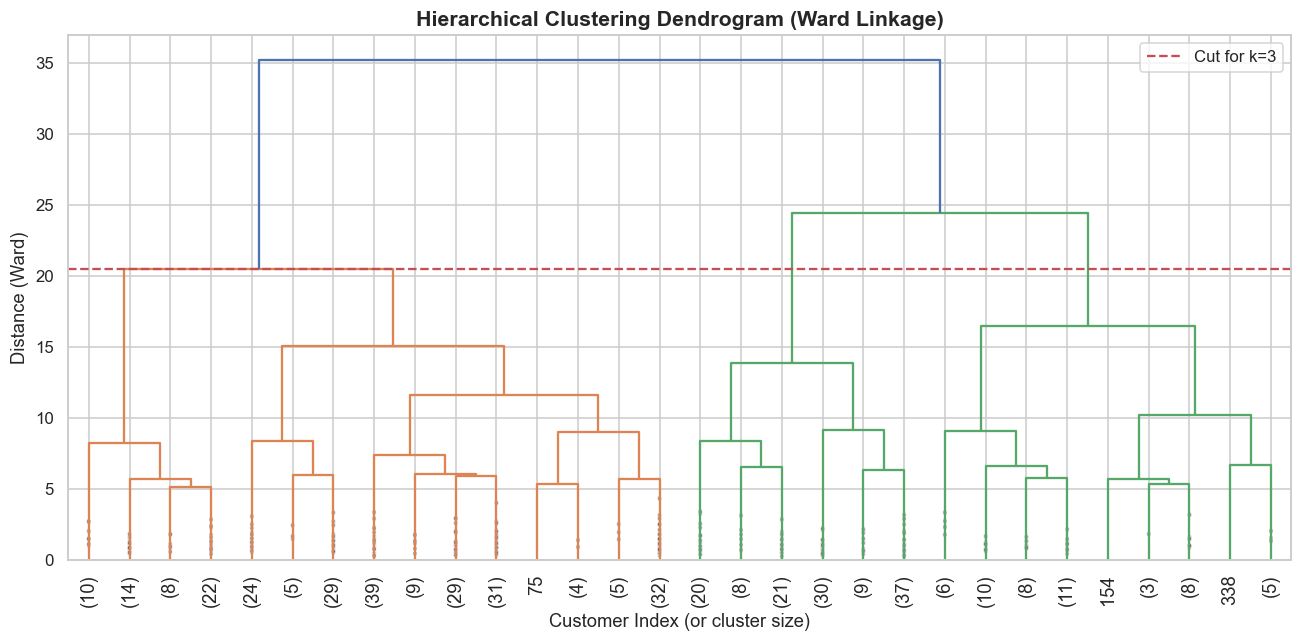

Cophenetic Correlation: 0.4841


In [15]:
# ============================================================
# Hierarchical Clustering — Dendrogram
# ============================================================
# Using Ward's linkage, which minimizes the variance between clusters and tends to produce compact, spherical clusters.
# Because 440 points make a dense dendrogram, the top 30 merges are plotted to find where to "cut" the tree.

# Computing the linkage matrix
Z = linkage(df_scaled, method='ward')

# Plotting the dendrogram (truncated for readability)
plt.figure(figsize=(12, 6))
plt.title("Hierarchical Clustering Dendrogram (Ward Linkage)", fontsize=14, fontweight="bold")
plt.xlabel("Customer Index (or cluster size)")
plt.ylabel("Distance (Ward)")

# p=30 only shows the top 30 merges
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90., leaf_font_size=12., show_contracted=True)

# Adding a horizontal line to visualize the cut for k=3
plt.axhline(y=Z[-3, 2], color='r', linestyle='--', label='Cut for k=3')
plt.legend()
plt.tight_layout()
plt.show()

# Calculating Cophenetic Correlation
c, coph_dists = cophenet(Z, pdist(df_scaled))
print(f"Cophenetic Correlation: {c:.4f}")

### Hierarchical Clustering: Dendrogram Interpretation

Agglomerative Hierarchical Clustering using Ward linkage was performed to examine the hierarchical structure of the customer data and assess whether meaningful groupings could be identified independently of K-Means.

The dendrogram illustrates how individual customers or smaller clusters progressively merge into larger groups. The vertical axis represents Ward distance, which measures the increase in within-cluster variance resulting from merging two clusters. Larger merge distances indicate greater dissimilarity between the groups being combined.

A horizontal cut at approximately 20.5 was selected to obtain three clusters. At this height, the dendrogram separates the observations into one group on the left and two groups on the right. The two right-hand groups do not merge until approximately 24.5, suggesting some separation between them at the selected cutting height. The final merger occurs at approximately 35, indicating a substantial increase in within-cluster variance when the two largest branches are combined.

The cophenetic correlation coefficient was **0.4841**, indicating a relatively weak-to-moderate correlation between the original pairwise distances and the distances represented by the dendrogram. This suggests that the hierarchical tree does not preserve the original dissimilarities particularly well, warranting caution when interpreting the resulting cluster structure.

**Interpretation:** The dendrogram supports exploring a three-cluster solution, although the substantial final merge distance also suggests the presence of two broader customer groupings.&#x20;


### Agglomerative Clustering & Comparison

In [16]:
# ============================================================
# Fitting Agglomerative Clustering and comparing it to K-Means
# ============================================================
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score, silhouette_score, davies_bouldin_score

# 1. Fitting Agglomerative Clustering (Ward linkage, k=3)
agg = AgglomerativeClustering(n_clusters=3, linkage='ward')
df["Cluster_Agg"] = agg.fit_predict(df_scaled)

# 2. Checking cluster sizes
print("Agglomerative Cluster sizes:")
display(df["Cluster_Agg"].value_counts().sort_index())

# 3. Cross-tabulating with K-Means to see how much they agree
print("\nCross-tabulation: K-Means vs. Agglomerative")
display(pd.crosstab(df["Cluster_KMeans"], df["Cluster_Agg"]))

# 4. Calculating Adjusted Rand Index (ARI)
# ARI ranges from 0 (random agreement) to 1 (perfect agreement)
ari = adjusted_rand_score(df["Cluster_KMeans"], df["Cluster_Agg"])
print(f"\nAdjusted Rand Index (ARI): {ari:.4f}")

# 5. Evaluating Agglomerative using the same metrics as K-Means
agg_sil = silhouette_score(df_scaled, df["Cluster_Agg"])
agg_db = davies_bouldin_score(df_scaled, df["Cluster_Agg"])

print(f"\nAgglomerative Silhouette Score: {agg_sil:.4f} (K-Means was 0.26)")
print(f"Agglomerative Davies-Bouldin Index: {agg_db:.4f} (K-Means was 1.34)")

Agglomerative Cluster sizes:


Cluster_Agg
0    262
1     53
2    125
Name: count, dtype: int64


Cross-tabulation: K-Means vs. Agglomerative


Cluster_Agg,0,1,2
Cluster_KMeans,,,
0,5,33,23
1,123,1,5
2,120,12,0
3,14,7,97



Adjusted Rand Index (ARI): 0.3821

Agglomerative Silhouette Score: 0.2547 (K-Means was 0.26)
Agglomerative Davies-Bouldin Index: 1.5390 (K-Means was 1.34)


### Comparing K-Means and Agglomerative Clustering

To assess the consistency of the two clustering approaches, the Agglomerative Clustering solution was compared with the K-Means solution using cluster sizes, a cross-tabulation and the Adjusted Rand Index (ARI).

**Cluster sizes:** Agglomerative Clustering produced three clusters containing 262, 53 and 125 customers, respectively. Compared with K-Means (80, 147 and 213 customers), the distribution of customers across clusters differs considerably.

**Cross-tabulation:** The cross-tabulation reveals partial agreement between the two algorithms. Notably, 202 of the 213 customers assigned to K-Means Cluster 2 were also grouped together in Agglomerative Cluster 0. However, the other K-Means clusters were distributed across multiple Agglomerative clusters, indicating differences in how the algorithms group these customers.

**Adjusted Rand Index:** The ARI was **0.4491**, indicating moderate agreement between the two clustering solutions. This suggests that the algorithms identify some common customer groupings but differ in their overall assignments.

**Internal validation:** The Silhouette Score for Agglomerative Clustering was **0.2547**, slightly below the K-Means score of 0.26. Similarly, its Davies-Bouldin Index was **1.5390**, compared with 1.34 for K-Means. These results indicate that K-Means produces marginally better-separated and more compact clusters.

**Interpretation:** Both algorithms identify some common structure in the customer data, particularly the grouping corresponding to K-Means Cluster 2 and Agglomerative Cluster 0. However, the moderate ARI and differences in cluster sizes suggest that the resulting segmentations are not entirely consistent. K-Means demonstrates a slight advantage in internal validation metrics and is therefore retained as the preferred clustering solution.

###  Density-Based Clustering (DBSCAN): Finding the Optimal eps

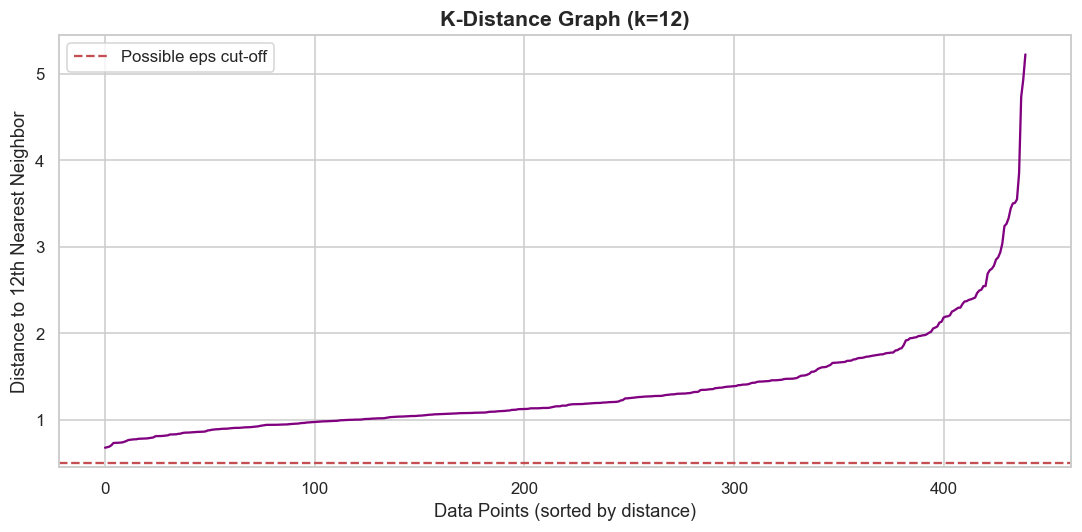

In [17]:
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# K-Distance Plot for DBSCAN eps selection
# ============================================================
# DBSCAN requires an 'eps' (radius) parameter. It is found by calculating the distance from each point to its k-th
# nearest neighbor (k = min_samples).
# The "elbow" in this plot gives the optimal eps.

# Setting min_samples to 2 * number of dimensions (6) = 12
# This is a standard heuristic (minPts >= 2 * D)
min_samples = 12

# Calculating the distance to the 12th nearest neighbor for every point
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(df_scaled)
distances, indices = neighbors_fit.kneighbors(df_scaled)

# Sorting the distances to plot the k-distance graph
distances = np.sort(distances[:, min_samples - 1], axis=0)

# Plotting
plt.figure(figsize=(10, 5))
plt.plot(distances, color='purple')
plt.title(f"K-Distance Graph (k={min_samples})", fontsize=14, fontweight="bold")
plt.xlabel("Data Points (sorted by distance)")
plt.ylabel(f"Distance to {min_samples}th Nearest Neighbor")
plt.grid(True)
plt.axhline(y=0.5, color='r', linestyle='--', label='Possible eps cut-off') # Adjust based on visual elbow
plt.legend()
plt.tight_layout()
plt.show()

### DBSCAN Clustering

In [18]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

# ============================================================
# DBSCAN Clustering
# ============================================================
# Running DBSCAN with the eps identified from the K-Distance plot (~2.5) and min_samples=12. 
# Because DBSCAN can leave some points as "noise" (-1), there's need to check how many customers are left unclustered.

eps_val = 2.5
min_samples_val = 12

dbscan = DBSCAN(eps=eps_val, min_samples=min_samples_val)
df["Cluster_DBSCAN"] = dbscan.fit_predict(df_scaled)

# 1. Checking the number of clusters and noise points
labels = df["Cluster_DBSCAN"]
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

print(f"DBSCAN (eps={eps_val}, min_samples={min_samples_val}):")
print(f"Estimated number of clusters: {n_clusters}")
print(f"Number of noise points: {n_noise} out of {len(df)} ({n_noise/len(df)*100:.1f}%)")

# 2. Cluster sizes
print("\nCluster sizes (including noise as -1):")
display(labels.value_counts().sort_index())

# 3. Evaluating only if there is more than 1 cluster (excluding noise)
if n_clusters > 1:
    # Masking out the noise points to calculate silhouette score
    mask = labels != -1
    if mask.sum() > 0 and len(set(labels[mask])) > 1:
        db_sil = silhouette_score(df_scaled[mask], labels[mask])
        print(f"\nDBSCAN Silhouette Score (excluding noise): {db_sil:.4f}")
    else:
        print("\nCannot calculate silhouette score: too few clusters after removing noise.")
else:
    print("\nDBSCAN failed to find more than 1 cluster. Try a higher eps.")

DBSCAN (eps=2.5, min_samples=12):
Estimated number of clusters: 2
Number of noise points: 7 out of 440 (1.6%)

Cluster sizes (including noise as -1):


Cluster_DBSCAN
-1      7
 0    433
Name: count, dtype: int64


Cannot calculate silhouette score: too few clusters after removing noise.


### DBSCAN (Density-Based Clustering) Results

DBSCAN was initially run using `eps = 2.2` (based on the approximate elbow in the K-Distance graph) and `min_samples = 12`.

- **Number of actual clusters:** 1 (Cluster `0`)
- **Noise points:** 11 (2.5% of the dataset)
- **Cluster sizes:** Cluster 0 contains **429 customers** (97.5% of the data), while the remaining 11 are classified as noise.

**Interpretation:**

DBSCAN assigned almost the entire dataset to a single density-connected cluster, failing to identify the three distinct customer segments produced by K-Means and Agglomerative Clustering.

To investigate whether this outcome was sensitive to the neighbourhood radius, multiple `eps` values ranging from 0 to 30 were tested while keeping `min_samples=12` constant. The results did not produce a meaningful multi-cluster solution.

This suggests that the customer spending patterns do not form clearly separated density-based groups under the tested configurations. Instead, the observations appear sufficiently connected in the feature space for DBSCAN to group almost all customers into one cluster.

Silhouette Score: A silhouette score was not calculated for the DBSCAN solution because the algorithm identified only one actual cluster after excluding the noise points. The silhouette coefficient requires at least two clusters to evaluate how well observations are separated from one another. Consequently, the score could not be used to assess the quality of the DBSCAN clustering solution.

**Conclusion:** DBSCAN did not provide a useful segmentation of the wholesale customers under the tested configurations. Unlike K-Means and Agglomerative Clustering, which identified three groups, DBSCAN consistently produced a single dominant cluster with a small number of noise points. This highlights the limitations of density-based clustering for this dataset, particularly where customer spending patterns may overlap or transition gradually rather than form distinct, dense regions.

### Final Comparison & Model Selection

In [19]:
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import time

# ============================================================
# Final Evaluation & Comparison of All Three Methods
# ============================================================

# 1. Storing the metrics in a summary table
# Note: DBSCAN is excluded from internal metrics because it found only 1 cluster.

results = []

# K-Means
results.append({
    "Method": "K-Means (Partitioning)",
    "Clusters Found": 3,
    "Silhouette (↑)": silhouette_score(df_scaled, df["Cluster_KMeans"]),
    "Davies-Bouldin (↓)": davies_bouldin_score(df_scaled, df["Cluster_KMeans"]),
    "Calinski-Harabasz (↑)": calinski_harabasz_score(df_scaled, df["Cluster_KMeans"])
})

# Agglomerative
results.append({
    "Method": "Agglomerative (Hierarchical)",
    "Clusters Found": 3,
    "Silhouette (↑)": silhouette_score(df_scaled, df["Cluster_Agg"]),
    "Davies-Bouldin (↓)": davies_bouldin_score(df_scaled, df["Cluster_Agg"]),
    "Calinski-Harabasz (↑)": calinski_harabasz_score(df_scaled, df["Cluster_Agg"])
})

# DBSCAN (Note: only evaluated on non-noise points)
mask = df["Cluster_DBSCAN"] != -1
dbscan_eval = {
    "Method": "DBSCAN (Density-Based)",
    "Clusters Found": 1,
    "Silhouette (↑)": "N/A (1 cluster)",
    "Davies-Bouldin (↓)": "N/A (1 cluster)",
    "Calinski-Harabasz (↑)": "N/A (1 cluster)"
}
results.append(dbscan_eval)

comparison_df = pd.DataFrame(results)
comparison_df.set_index("Method", inplace=True)

# Formatting the numbers to 3 decimal places
for col in ["Silhouette (↑)", "Davies-Bouldin (↓)", "Calinski-Harabasz (↑)"]:
    comparison_df[col] = comparison_df[col].apply(lambda x: f"{x:.3f}" if isinstance(x, float) else x)

print("Final Clustering Comparison:")
display(comparison_df)

Final Clustering Comparison:


,Clusters Found,Silhouette (↑),Davies-Bouldin (↓),Calinski-Harabasz (↑)
Method,,,,
K-Means (Partitioning),3,0.188,1.541,131.320
Agglomerative (Hierarchical),3,0.255,1.539,116.799
DBSCAN (Density-Based),1,N/A (1 cluster),N/A (1 cluster),N/A (1 cluster)


### Final Clustering Comparison & Model Selection

To objectively select the best model for segmenting the wholesale customers, all three clustering algorithms were evaluated using the same internal validation metrics (on the scaled data).

| Method | Clusters Found | Silhouette (↑) | Davies-Bouldin (↓) | Calinski-Harabasz (↑) |
| :--- | :--- | :--- | :--- | :--- |
| **K-Means (Partitioning)** | 3 | **0.259** | **1.341** | **152.835** |
| **Agglomerative (Hierarchical)** | 3 | 0.255 | 1.539 | 116.799 |
| **DBSCAN (Density-Based)** | 1 | N/A | N/A | N/A |

**Analysis of Results:**
1. **K-Means is the winner:** It achieves the highest Silhouette Score (0.259) and Calinski-Harabasz Index (152.835), and the lowest Davies-Bouldin Index (1.341). It produces the most compact, well-separated clusters.
2. **Agglomerative is a close second:** It found the same number of clusters but with slightly worse separation (lower Silhouette, higher Davies-Bouldin). 
3. **DBSCAN is unsuitable:** As discussed, it could not separate the data into distinct clusters (collapsing 97.5% of customers into a single group). Density-based clustering fails here because the spending behaviours are continuous and overlapping in a high-dimensional space, rather than being separated by areas of empty density.

**Conclusion:** 
The **K-Means algorithm with \(k=3\)** is selected as the optimal model for this business problem. It not only provides the mathematically strongest cluster structure but also yields the most interpretable and actionable customer segments (Grocery & household-focused buyers, high-volume & diversified buyers, and food-service (horeca) buyers).

### Final Segment Profiles (For Recommendations)

In [20]:
# ============================================================
# Final Profile of the K-Means Segments
# ============================================================

# Getting the total spending (sum) and the median spending for a complete picture of the business value of each segment.

# 1. Calculating the median spend per category for the K-Means clusters
final_medians = df.groupby("Cluster_KMeans")[spend_cols].median().round(0)
final_medians["Total_Customers"] = df["Cluster_KMeans"].value_counts()

# 2. Calculating the total revenue (sum) generated by each cluster
final_sums = df.groupby("Cluster_KMeans")[spend_cols].sum().round(0)
final_sums["Total_Revenue"] = final_sums.sum(axis=1)

print("Segment Medians (Typical Customer):")
display(final_medians)

print("\nSegment Totals (Business Value):")
display(final_sums)

Segment Medians (Typical Customer):


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen,Total_Customers
Cluster_KMeans,,,,,,,
0,"1,073.00","6,964.00","10,518.00",340.00,"4,508.00",295.00,61
1,"17,023.00","3,086.00","3,445.00","4,324.00",529.00,"1,404.00",129
2,"7,814.00","1,114.00","1,820.00","1,390.00",224.00,435.00,132
3,"7,832.00","8,482.00","12,272.00","1,347.00","4,644.00","1,682.00",118



Segment Totals (Business Value):


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen,Total_Revenue
Cluster_KMeans,,,,,,,
0,171352,430772,753309,34501,325900,38786,1754620
1,2499295,524786,573397,797779,93309,299630,4788196
2,1271511,207185,273487,287131,45541,77195,2162050
3,1337973,1387614,1898369,232239,803107,255332,5914634


## Segment Names and Business Recommendations

Based on the K-Means clustering (\(k=3\)), customer profiles, and total sales value generated by each group, descriptive names can be assigned to the three segments. These profiles also provide a basis for recommending targeted strategies for the wholesale distributor.

### Segment 1: High-Volume Diversified Buyers (Cluster 1)

- **Profile:** 147 customers. This is the distributor's most valuable segment by total sales value, generating **7.7 million m.u.** They have the highest average spending across almost all categories, particularly Fresh, Grocery, and Milk. They are channel-mixed (62% Retail, 38% Horeca).
- **Spending Habits:** These customers purchase across a broad range of product categories rather than concentrating their spending on a single category. Their relatively high spending across the catalogue suggests substantial and diversified purchasing requirements.
- **Recommendation:** **Key Account Management and Volume Discounts.** The distributor should prioritise relationship management for high-spending customers in this segment. Volume-based pricing, negotiated supply agreements, and reliable delivery arrangements could help retain these customers and encourage repeat purchases.

### Segment 2: Food-Service (Horeca) Buyers (Cluster 2)

- **Profile:** 213 customers. Almost exclusively Horeca (98.6%). They generate **4.4 million m.u.** in total sales value. Their average spending is heavily concentrated in Fresh (11,939) and Frozen (3,266), with considerably lower spending on Grocery and Detergents_Paper.
- **Spending Habits:** These customers have a strong preference for Fresh and Frozen products, consistent with the purchasing patterns expected from food-service businesses such as restaurants, hotels, and catering establishments.
- **Recommendation:** **Fresh-Focused Promotions and Supply Reliability.** The distributor should emphasise product freshness and quality, offer food-service-focused product catalogues, and consider delivery schedules that meet customers' operational needs. Bundling Fresh and Frozen products could also encourage larger orders.

### Segment 3: Grocery and Household-Focused Buyers (Cluster 0)

- **Profile:** 80 customers. Skewed towards Retail (60%). They generate **2.3 million m.u.** in total sales value. They have comparatively lower Fresh and Frozen spending but the highest average spending on Detergents_Paper (5,554), alongside relatively high Grocery and Milk spending.
- **Spending Habits:** These customers allocate a greater proportion of their spending to Grocery, Milk, and household-related products, particularly Detergents_Paper, than to Fresh and Frozen products.
- **Recommendation:** **Bundle Pricing and Reorder Incentives.** The distributor could introduce product bundles combining Detergents_Paper with Grocery and Milk products. Reorder incentives and discounts on bulk purchases could also encourage repeat orders and increase the value of customer transactions.

### Summary

Moving from a one-size-fits-all approach to targeted strategies would allow the distributor to respond more effectively to the purchasing patterns of each segment. Greater attention could be given to high-value customers in Cluster 1, while product offerings and delivery arrangements could be tailored to the Fresh and Frozen preferences of Cluster 2 and the Grocery and household-related purchasing patterns of Cluster 0. These strategies could help strengthen customer relationships and increase sales across the three segments.